# Étape 2 — Prétraitement des données

**Objectif :** transformer les données brutes en une table **propre et prête pour la fouille de données** (data mining).

**Périmètre :** les **analyses de gaz dissous** des **transformateurs**. C'est la mesure principale utilisée pour diagnostiquer un transformateur.

**Plan :**
1. Importer les bibliothèques
2. Charger les données brutes (CSV de l'étape 1)
3. Construire la table d'étude
4. Types de données
5. Les « faux zéros »
6. Valeurs manquantes (NA)
7. Doublons
8. Statistiques descriptives (`describe`)
9. Traitement des valeurs manquantes
10. Valeurs aberrantes
11. Transformation logarithmique
12. Normalisation et standardisation
13. Analyse en composantes principales (ACP)
14. Sauvegarde de la table prétraitée

## 1. Importer les bibliothèques

In [1]:
from pathlib import Path

import numpy as np                 # calculs numériques (logarithme, racine carrée...)
import pandas as pd                # tableaux de données
import matplotlib.pyplot as plt    # graphiques
import seaborn as sns              # graphiques statistiques (boxplots...)

# scikit-learn : bibliothèque de machine learning
from sklearn.preprocessing import MinMaxScaler, StandardScaler   # normalisation / standardisation
from sklearn.decomposition import PCA                            # ACP (PCA en anglais)

# Apparence des graphiques
sns.set_theme(style="whitegrid")
BLEU, ORANGE = "#2a78d6", "#eb6834"

# Afficher les nombres avec 2 décimales et toutes les colonnes
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

print("Bibliothèques importées.")

Bibliothèques importées.


## 2. Charger les données brutes
On repart des fichiers CSV créés à l'étape 1 (dossier `data/raw/`). Trois tables suffisent :

| Fichier | Contenu |
|---|---|
| `Equipement.csv` | caractéristiques des 900 équipements |
| `Analyse.csv` | les prélèvements d'huile (date, type d'essai, équipement) |
| `Gaz_Dissous.csv` | les concentrations de gaz mesurées (en ppm) |

In [2]:
dossier_raw = Path.cwd() / "data" / "raw"

# dtype={"NoÉquipement": str} : on force le numéro d'équipement à rester du TEXTE.
# Sans cela, pandas lirait "11001" comme un nombre mais "T0101" comme du texte : la colonne serait incohérente.
equipements = pd.read_csv(dossier_raw / "Equipement.csv", dtype={"NoÉquipement": str})
analyses = pd.read_csv(dossier_raw / "Analyse.csv", dtype={"NoÉquipement": str})
gaz_dissous = pd.read_csv(dossier_raw / "Gaz_Dissous.csv", dtype={"NoÉquipement": str})

print("Équipements :", equipements.shape)
print("Analyses    :", analyses.shape)
print("Gaz dissous :", gaz_dissous.shape)

Équipements : (900, 12)
Analyses    : (11703, 20)
Gaz dissous : (5090, 13)


## 3. Construire la table d'étude
On veut une table où **une ligne = un prélèvement de gaz dissous sur un transformateur**, avec :
- la **date** du prélèvement (table `Analyse`) ;
- les **caractéristiques du transformateur** (table `Équipement`) ;
- les **concentrations de gaz** (table `Gaz Dissous`).

On procède en 3 temps : on garde seulement les transformateurs, puis seulement les analyses de gaz dissous, puis on **joint** les tables.

In [3]:
# 3.1 Garder uniquement les transformateurs (code "T")
transformateurs = equipements[equipements["TypeÉquipement"] == "T"]

# On ne garde que les colonnes utiles du transformateur
transformateurs = transformateurs[["NoÉquipement", "Site", "Manufacturier", "Année", "Tension", "Puissance", "LitreHuile"]]
print("Nombre de transformateurs :", len(transformateurs))

Nombre de transformateurs : 432


In [4]:
# 3.2 Garder uniquement les analyses de gaz dissous (code "GD") et les colonnes utiles
analyses_gd = analyses[analyses["TypeAnalyse"] == "GD"]
analyses_gd = analyses_gd[["CléAnalyse", "NoÉquipement", "DatePrélèvement"]]
print("Nombre d'analyses de gaz dissous (tous équipements) :", len(analyses_gd))

Nombre d'analyses de gaz dissous (tous équipements) : 5101


In [5]:
# 3.3 Joindre les tables (merge = "coller" les colonnes de deux tables qui ont une colonne commune)
# - how="inner" : on garde seulement les lignes présentes dans les DEUX tables.
#   Donc les analyses faites sur autre chose qu'un transformateur disparaissent automatiquement.
# - Le numéro d'équipement est pris dans la table Analyse ; on retire celui de Gaz Dissous pour ne pas l'avoir en double.
table = gaz_dissous.drop(columns=["NoÉquipement"])
table = table.merge(analyses_gd, on="CléAnalyse", how="inner")
table = table.merge(transformateurs, on="NoÉquipement", how="inner")

# On range les colonnes dans un ordre logique : identifiants, date, transformateur, gaz
ordre_colonnes = ["CléAnalyse", "NoÉquipement", "DatePrélèvement",
                  "Site", "Manufacturier", "Année", "Tension", "Puissance", "LitreHuile",
                  "H2", "CH4", "C2H2", "C2H4", "C2H6", "CO", "CO2", "O2", "N2", "MWs", "Température"]
table = table[ordre_colonnes]

print("Table d'étude :", table.shape[0], "prélèvements,", table.shape[1], "colonnes")
print("Nombre de transformateurs concernés :", table["NoÉquipement"].nunique())
table.head()

Table d'étude : 4363 prélèvements, 20 colonnes
Nombre de transformateurs concernés : 293


,CléAnalyse,NoÉquipement,DatePrélèvement,Site,Manufacturier,Année,Tension,Puissance,LitreHuile,H2,CH4,C2H2,C2H4,C2H6,CO,CO2,O2,N2,MWs,Température
0,AM0000000018605,T0101,1994-12-19,CCD,CGE,0.00,161.00,"20,000.00","19,321.00",115.00,14.00,0.00,14.00,16.00,914.00,"8,860.00","2,658.00","64,007.00",0.00,0.00
1,AM0000000018606,T0101,1995-05-25,CCD,CGE,0.00,161.00,"20,000.00","19,321.00",83.00,19.00,0.00,15.00,16.00,825.00,"8,612.00",389.00,"61,198.00",0.00,0.00
2,AM0000000018607,T0101,1995-09-06,CCD,CGE,0.00,161.00,"20,000.00","19,321.00",82.00,18.00,0.00,17.00,15.00,806.00,"9,539.00",347.00,"60,498.00",0.00,0.00
3,AM0000000018608,T0102,1995-09-06,CCD,CGE,0.00,161.00,"20,000.00","19,321.00",35.00,8.00,0.30,37.00,6.70,463.00,"3,824.00","17,021.00","68,553.00",0.00,0.00
4,AM0000000018609,T0102,1994-12-19,CCD,CGE,0.00,161.00,"20,000.00","19,321.00",25.00,5.30,0.00,28.00,6.00,411.00,"3,300.00","16,889.00","64,216.00",0.00,0.00


**Interprétation :** sur les 432 transformateurs de la base, environ **290 ont au moins une analyse de gaz dissous**.
Les autres n'ont jamais eu ce type d'analyse (ils ont pu avoir d'autres essais, ou aucun).

## 4. Types de données
`info()` affiche, pour chaque colonne, son **type** et le nombre de valeurs **non vides**.

In [6]:
table.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4363 entries, 0 to 4362
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CléAnalyse       4363 non-null   object 
 1   NoÉquipement     4363 non-null   object 
 2   DatePrélèvement  4355 non-null   object 
 3   Site             4363 non-null   object 
 4   Manufacturier    4363 non-null   object 
 5   Année            4363 non-null   float64
 6   Tension          4363 non-null   float64
 7   Puissance        4363 non-null   float64
 8   LitreHuile       4363 non-null   float64
 9   H2               4363 non-null   float64
 10  CH4              4363 non-null   float64
 11  C2H2             4363 non-null   float64
 12  C2H4             4363 non-null   float64
 13  C2H6             4363 non-null   float64
 14  CO               4363 non-null   float64
 15  CO2              4363 non-null   float64
 16  O2               4363 non-null   float64
 17  N2            

La date est lue comme du **texte** (`object`). On la convertit en vrai type **date** pour pouvoir faire des calculs (années, durées…).

In [7]:
# errors="coerce" : si une date est illisible, elle devient une valeur manquante (NaT) au lieu de provoquer une erreur
table["DatePrélèvement"] = pd.to_datetime(table["DatePrélèvement"], errors="coerce")
print("Type de DatePrélèvement :", table["DatePrélèvement"].dtype)

Type de DatePrélèvement : datetime64[ns]


**Nature des variables :**

| Nature | Colonnes |
|---|---|
| Identifiants (pas des variables d'analyse) | `CléAnalyse`, `NoÉquipement` |
| Date | `DatePrélèvement` |
| Qualitatives (catégories) | `Site`, `Manufacturier` |
| Quantitatives — caractéristiques du transformateur | `Année`, `Tension` (kV), `Puissance` (kVA), `LitreHuile` (L) |
| Quantitatives — gaz de défaut (ppm) | `H2`, `CH4`, `C2H2`, `C2H4`, `C2H6`, `CO`, `CO2` |
| Quantitatives — gaz de l'air (ppm) | `O2`, `N2` |
| Quantitatives — autres | `MWs`, `Température` |

## 5. Les « faux zéros »
Dans cette base ancienne, quand une valeur n'était pas connue, on saisissait souvent **0** au lieu de laisser la case vide.
Ces zéros sont donc des **valeurs manquantes déguisées** : si on les laisse, les moyennes seront fausses.

Regardons d'abord la part de zéros dans chaque colonne numérique :

In [8]:
colonnes_numeriques = table.select_dtypes("number").columns

# (table == 0).mean() donne la proportion de zéros ; x 100 pour avoir un pourcentage
pourcentage_zeros = ((table[colonnes_numeriques] == 0).mean() * 100).round(1)
pourcentage_zeros.sort_values(ascending=False).to_frame("% de zéros")

,% de zéros
MWs,100.00
Température,91.20
C2H2,55.40
Année,39.00
Puissance,29.70
C2H6,13.40
CH4,4.10
C2H4,3.70
Tension,2.50
H2,1.90


**Quels zéros sont impossibles ?**

| Colonne | Un 0 est-il possible ? | Décision |
|---|---|---|
| `MWs` | toujours 0 → colonne jamais remplie | 0 → NA |
| `Température` | 91 % de 0 → valeur non saisie | 0 → NA |
| `Année`, `Tension`, `Puissance`, `LitreHuile` | un transformateur n'a pas 0 kV, 0 kVA, 0 litre ni l'an 0 | 0 → NA |
| `O2`, `N2` | ce sont des gaz de l'air, toujours présents dans l'huile | 0 → NA |
| `CO`, `CO2` | produits en permanence par le vieillissement normal du papier isolant : jamais exactement 0 | 0 → NA |
| `H2`, `CH4`, `C2H2`, `C2H4`, `C2H6` | **oui** : 0 ppm = « gaz non détecté » (état normal d'un transformateur sain) | **on garde le 0** |

Cas particulier : si **tous** les gaz de défaut sont à 0 en même temps, le prélèvement n'a en réalité pas été mesuré → on supprime la ligne.
On fait ce test **en premier**, avant de transformer les zéros en NA.

In [9]:
# 5.1 Supprimer les prélèvements où tous les gaz de défaut valent 0
gaz_defaut = ["H2", "CH4", "C2H2", "C2H4", "C2H6", "CO", "CO2"]
tous_a_zero = (table[gaz_defaut] == 0).all(axis=1)     # True si les 7 gaz valent 0 sur la ligne
print("Prélèvements entièrement à zéro (supprimés) :", tous_a_zero.sum())

table = table[~tous_a_zero]                             # ~ signifie "NON" : on garde les lignes qui ne sont pas toutes à 0

# 5.2 Remplacer les zéros impossibles par NA (np.nan = "Not a Number" = valeur manquante)
colonnes_zero_impossible = ["MWs", "Température", "Année", "Tension", "Puissance", "LitreHuile", "O2", "N2", "CO", "CO2"]
table[colonnes_zero_impossible] = table[colonnes_zero_impossible].replace(0, np.nan)

print("Table après traitement des faux zéros :", table.shape)

Prélèvements entièrement à zéro (supprimés) : 10
Table après traitement des faux zéros : (4353, 20)


## 6. Valeurs manquantes (NA)
Maintenant que les faux zéros sont devenus des NA, on peut compter les **vraies** valeurs manquantes.

In [10]:
nombre_na = table.isna().sum()                       # nombre de NA par colonne
pourcentage_na = (table.isna().mean() * 100).round(1)  # pourcentage de NA par colonne

resume_na = pd.DataFrame({"nombre_NA": nombre_na, "pourcentage_NA": pourcentage_na})
resume_na = resume_na[resume_na["nombre_NA"] > 0].sort_values("pourcentage_NA", ascending=False)
resume_na

,nombre_NA,pourcentage_NA
MWs,4353,100.00
Température,3968,91.20
Année,1699,39.00
Puissance,1292,29.70
Tension,107,2.50
LitreHuile,26,0.60
N2,22,0.50
CO,2,0.00
CO2,1,0.00
O2,2,0.00


**Interprétation :**
- `MWs` (100 %) et `Température` (~ 91 %) sont **presque vides** : elles ne pourront pas être utilisées.
- `Puissance` et `Année` sont inconnues pour **un tiers** des prélèvements environ : information utile mais incomplète.
- `Tension`, `LitreHuile`, `O2` et `N2` ont **très peu** de valeurs manquantes.
- Les gaz de défaut sont **quasiment complets** (seulement 3 valeurs de `CO`/`CO2` manquantes) : notre variable principale est de bonne qualité.

Le traitement de ces NA est fait à la section 9.

## 7. Doublons
On vérifie trois niveaux de doublons :
1. des lignes **strictement identiques** ;
2. une même **clé d'analyse** (`CléAnalyse`) présente deux fois ;
3. un même transformateur, le **même jour**, avec **exactement les mêmes résultats** de gaz, mais sous deux numéros d'analyse différents (saisie en double).

In [11]:
# 1. Lignes entièrement identiques
print("Lignes strictement identiques :", table.duplicated().sum())

# 2. Clé d'analyse en double
print("CléAnalyse en double         :", table["CléAnalyse"].duplicated().sum())

# 3. Même transformateur + même date + mêmes valeurs de gaz
colonnes_comparees = ["NoÉquipement", "DatePrélèvement"] + gaz_defaut
doublons_caches = table.duplicated(subset=colonnes_comparees)
print("Saisies en double (même transfo, même jour, mêmes gaz) :", doublons_caches.sum())

Lignes strictement identiques : 0
CléAnalyse en double         : 0
Saisies en double (même transfo, même jour, mêmes gaz) : 15


In [12]:
# Exemple : on affiche une paire de doublons cachés pour bien voir le problème
exemple = table[table.duplicated(subset=colonnes_comparees, keep=False)]   # keep=False : montre les 2 exemplaires
exemple.sort_values(["NoÉquipement", "DatePrélèvement"]).head(4)[["CléAnalyse"] + colonnes_comparees]

,CléAnalyse,NoÉquipement,DatePrélèvement,H2,CH4,C2H2,C2H4,C2H6,CO,CO2
1007,AM0000000025349,T0202,1992-03-18,80.00,225.00,4.00,369.00,180.00,364.00,"3,470.00"
1021,AM0000000025474,T0202,1992-03-18,80.00,225.00,4.00,369.00,180.00,364.00,"3,470.00"
2981,SY0010000014078,T0204,2001-04-13,4.80,2.70,0.00,9.40,1.00,237.00,"3,345.00"
2982,SY0010000014162,T0204,2001-04-13,4.80,2.70,0.00,9.40,1.00,237.00,"3,345.00"


**Interprétation :** aucune ligne n'est strictement identique, car chaque analyse a son propre numéro.
Mais certains prélèvements ont été **saisis deux fois** sous deux numéros différents. On garde le premier exemplaire et on supprime l'autre :
sinon ces prélèvements compteraient double dans les statistiques.

In [13]:
# drop_duplicates : supprime les doublons ; keep="first" garde la première occurrence
table = table.drop_duplicates(subset=colonnes_comparees, keep="first")
print("Table après suppression des doublons :", table.shape)

Table après suppression des doublons : (4338, 20)


## 8. Statistiques descriptives (`describe`)
`describe()` donne, pour chaque colonne numérique : le nombre de valeurs, la moyenne (`mean`), l'écart-type (`std`),
le minimum, les quartiles (25 %, 50 % = médiane, 75 %) et le maximum.

In [ ]:
table[gaz_defaut + ["O2", "N2"]].describe().T

**Interprétation :**
- Pour tous les gaz de défaut, la **moyenne est bien plus grande que la médiane** (50 %). Exemple : pour `C2H2` (acétylène), la médiane vaut 0
  alors que la moyenne est tirée vers le haut par quelques valeurs énormes. Les distributions sont donc **très asymétriques**.
- Les **maximums** sont des centaines, voire des milliers de fois plus grands que la médiane : ce sont les transformateurs en défaut.
- Les gaz ont des **ordres de grandeur très différents** : quelques ppm pour `C2H2`, des milliers de ppm pour `CO2`.

Ces trois constats justifient la suite : imputer par la **médiane**, appliquer un **logarithme** et **standardiser**.

In [14]:
# Les caractéristiques des transformateurs
table[["Année", "Tension", "Puissance", "LitreHuile"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Année,"2,645.00","1,959.65",11.13,"1,937.00","1,959.00","1,959.00","1,961.00","2,004.00"
Tension,"4,231.00",184.53,123.73,2.40,161.00,161.00,345.00,690.00
Puissance,"3,052.00","31,008.62","55,864.09",25.00,"1,600.00","20,000.00","21,250.00","248,000.00"
LitreHuile,"4,314.00","22,701.57","19,397.54",68.00,"10,800.00","21,186.00","35,400.00","97,739.00"


## 9. Traitement des valeurs manquantes
Trois règles simples :

| Situation | Règle |
|---|---|
| Colonne vide à plus de 50 % | **supprimer la colonne** (trop peu d'information pour la compléter) |
| Date manquante | **supprimer la ligne** (une date ne peut pas être inventée) |
| Autre colonne numérique | **remplacer par la médiane** |
| Colonne texte (qualitative) | **remplacer par le mode** (la valeur la plus fréquente) |

### 9.1 Supprimer les colonnes vides à plus de 50 %

In [15]:
pourcentage_na = table.isna().mean() * 100
colonnes_a_supprimer = pourcentage_na[pourcentage_na > 50].index.tolist()
print("Colonnes supprimées :", colonnes_a_supprimer)

table = table.drop(columns=colonnes_a_supprimer)

Colonnes supprimées : ['MWs', 'Température']


### 9.2 Lignes sans date
Une date ne peut pas être inventée : une ligne sans date doit être supprimée.

In [16]:
print("Lignes sans date :", table["DatePrélèvement"].isna().sum())
table = table.dropna(subset=["DatePrélèvement"])   # dropna supprime les lignes ayant un NA dans la colonne indiquée
print("Table :", table.shape)

Lignes sans date : 0
Table : (4338, 18)


Il n'en reste **aucune** : les 8 dates manquantes du départ appartenaient aux prélèvements vides supprimés à la section 5.

### 9.3 Moyenne ou médiane ?
Le cours propose d'imputer par la **moyenne**, la **médiane** ou le **mode**. Comparons moyenne et médiane sur les colonnes à compléter :

In [17]:
colonnes_a_imputer = ["Année", "Tension", "Puissance", "LitreHuile", "CO", "CO2", "O2", "N2"]

comparaison = pd.DataFrame({
    "moyenne": table[colonnes_a_imputer].mean(),
    "médiane": table[colonnes_a_imputer].median(),
    "nombre_NA": table[colonnes_a_imputer].isna().sum(),
})
comparaison

,moyenne,médiane,nombre_NA
Année,"1,959.65","1,959.00",1693
Tension,184.53,161.00,107
Puissance,"31,008.62","20,000.00",1286
LitreHuile,"22,701.57","21,186.00",24
CO,503.66,402.00,2
CO2,"3,407.38","3,016.00",1
O2,"13,544.35","12,992.50",2
N2,"63,514.51","62,999.00",22


**Choix : la médiane.** Pour `Puissance` notamment, la moyenne (≈ 31 000 kVA) est très éloignée de la médiane (20 000 kVA),
car quelques très gros transformateurs la tirent vers le haut. C'est aussi le cas, dans une moindre mesure, pour `Tension`. La médiane représente mieux un transformateur « typique »
et n'est pas influencée par les valeurs extrêmes.

**Attention :** `Année` est inconnue pour environ un tiers des prélèvements. On l'impute pour avoir une table complète,
mais on garde une colonne `Année_imputée` (vrai/faux) pour pouvoir écarter ces lignes si on étudie l'âge plus tard.

In [18]:
# On mémorise où l'année était inconnue AVANT de la remplacer
table["Année_imputée"] = table["Année"].isna()

# Imputation par la médiane : fillna remplace les NA par la valeur donnée
for colonne in colonnes_a_imputer:
    mediane = table[colonne].median()
    table[colonne] = table[colonne].fillna(mediane)
    print(f"{colonne:11s} : NA remplacés par la médiane = {mediane:,.1f}")

Année       : NA remplacés par la médiane = 1,959.0
Tension     : NA remplacés par la médiane = 161.0
Puissance   : NA remplacés par la médiane = 20,000.0
LitreHuile  : NA remplacés par la médiane = 21,186.0
CO          : NA remplacés par la médiane = 402.0
CO2         : NA remplacés par la médiane = 3,016.0
O2          : NA remplacés par la médiane = 12,992.5
N2          : NA remplacés par la médiane = 62,999.0


### 9.4 Colonnes qualitatives : mode et harmonisation
Pour une colonne texte, on ne peut pas calculer de moyenne ni de médiane : on utilise le **mode** (la valeur la plus fréquente).

In [19]:
# .mode() renvoie la valeur la plus fréquente ; [0] prend la première
mode_fabricant = table["Manufacturier"].mode()[0]
print("NA dans Manufacturier :", table["Manufacturier"].isna().sum(), "| mode =", mode_fabricant)
print("NA dans Site          :", table["Site"].isna().sum())

table["Manufacturier"] = table["Manufacturier"].fillna(mode_fabricant)   # sans effet ici, mais la règle est en place

NA dans Manufacturier : 0 | mode = CGE
NA dans Site          : 0


Ici, aucune valeur qualitative ne manque. En revanche, la liste des fabricants révèle un autre problème de qualité :
**un même fabricant écrit de plusieurs façons**.

In [20]:
table["Manufacturier"].value_counts()

Manufacturier
CGE       1559
WEST      1091
ENG E      760
FER P      299
BROWN      264
BB         163
BALTE       55
F P         47
NEI         34
MICAF       30
ASEA         8
S.P.S        7
PIONE        7
BBC          5
SUPRE        3
asea         2
ABB          2
ASAE         1
Pauwel       1
Name: count, dtype: int64

`ASEA`, `asea` et `ASAE` (faute de frappe) désignent le même fabricant ; `FER P` et `F P` sont deux abréviations de Ferranti-Packard.
Sans correction, ils seraient comptés comme des fabricants différents. On harmonise : tout en majuscules, puis on regroupe les variantes.

In [21]:
# 1. Tout en majuscules et sans espaces au début ou à la fin
table["Manufacturier"] = table["Manufacturier"].str.upper().str.strip()

# 2. Regrouper les variantes d'un même fabricant (ancienne écriture -> écriture retenue)
corrections = {"ASAE": "ASEA", "F P": "FER P"}
table["Manufacturier"] = table["Manufacturier"].replace(corrections)

print("Nombre de fabricants différents :", table["Manufacturier"].nunique())

Nombre de fabricants différents : 16


In [22]:
# Vérification : il ne doit plus rester aucune valeur manquante
print("Nombre total de NA restants :", table.isna().sum().sum())
print("Table :", table.shape)

Nombre total de NA restants : 0
Table : (4338, 19)


## 10. Valeurs aberrantes
Une valeur aberrante est une valeur **très éloignée des autres**. Il faut en distinguer deux sortes :
- les **erreurs** (valeur physiquement impossible, faute de saisie) → à corriger ;
- les **valeurs extrêmes réelles** → à **garder**. Dans notre cas, un pic de gaz est **le signe d'un défaut** du transformateur :
  c'est précisément ce que l'on cherche à détecter !

### 10.1 Visualisation avec des boxplots
Dans un boxplot, la boîte va du 1er au 3e quartile, le trait central est la médiane, et les points isolés sont les valeurs aberrantes.

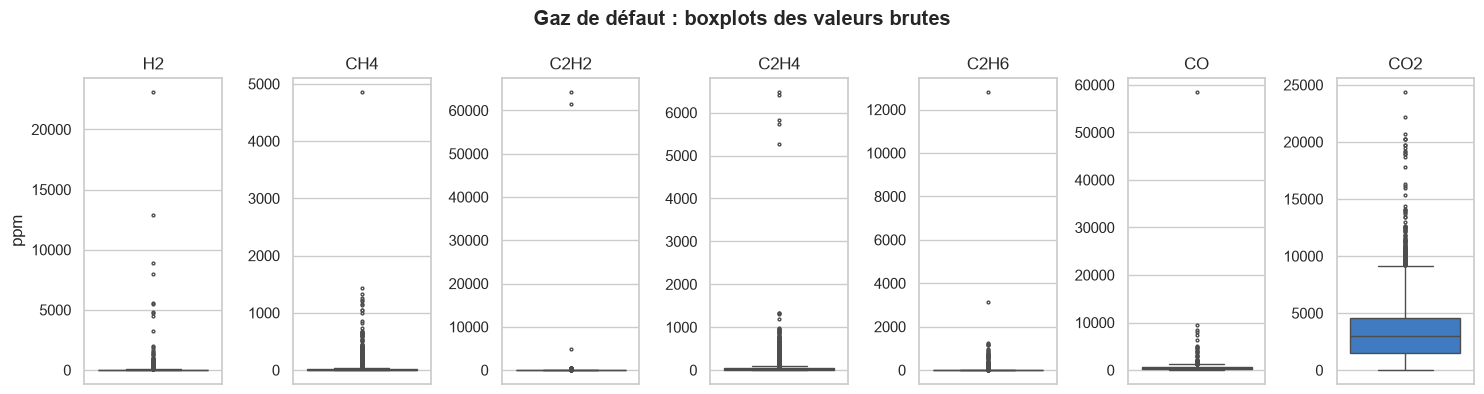

In [23]:
fig, axes = plt.subplots(1, 7, figsize=(15, 4))

# Un boxplot par gaz, car leurs échelles sont trop différentes pour un seul graphique
for i, gaz in enumerate(gaz_defaut):
    sns.boxplot(y=table[gaz], ax=axes[i], color=BLEU, fliersize=2)
    axes[i].set_title(gaz)
    axes[i].set_ylabel("ppm" if i == 0 else "")

fig.suptitle("Gaz de défaut : boxplots des valeurs brutes", fontweight="bold")
plt.tight_layout()
plt.show()

**Interprétation :** les boîtes sont **écrasées en bas** et on ne voit presque que des points isolés très hauts.
La grande majorité des prélèvements ont des valeurs faibles, et une minorité a des valeurs énormes.

### 10.2 Détection par la méthode IQR (écart interquartile)
Règle du cours : une valeur est aberrante si elle est en dehors de l'intervalle
**[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]**, avec IQR = Q3 − Q1.

In [24]:
resultats = []
for gaz in gaz_defaut:
    q1 = table[gaz].quantile(0.25)
    q3 = table[gaz].quantile(0.75)
    iqr = q3 - q1
    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr
    nb_aberrantes = ((table[gaz] < borne_basse) | (table[gaz] > borne_haute)).sum()
    resultats.append({"gaz": gaz, "Q1": q1, "Q3": q3, "IQR": iqr, "borne_haute": borne_haute,
                      "nb_aberrantes": nb_aberrantes,
                      "%_aberrantes": round(100 * nb_aberrantes / len(table), 1)})

pd.DataFrame(resultats)

,gaz,Q1,Q3,IQR,borne_haute,nb_aberrantes,%_aberrantes
0,H2,7.40,37.00,29.60,81.40,399,9.20
1,CH4,2.70,14.00,11.30,30.95,453,10.40
2,C2H2,0.00,0.80,0.80,2.00,357,8.20
3,C2H4,8.90,45.00,36.10,99.15,277,6.40
4,C2H6,1.10,9.70,8.60,22.60,443,10.20
5,CO,247.00,649.00,402.00,"1,252.00",132,3.00
6,CO2,"1,514.00","4,579.50","3,065.50","9,177.75",120,2.80


**Interprétation :**
- La méthode IQR signale **beaucoup** de valeurs : jusqu'à 10 % des prélèvements pour certains gaz.
- Pour `C2H2`, Q1 = 0 et Q3 = 0,8 ppm : dès **2 ppm** d'acétylène, un prélèvement est jugé « aberrant » ! Or l'acétylène est justement
  le signe d'un arc électrique, le défaut le plus grave.
- La méthode IQR suppose des données à peu près **symétriques**, ce qui n'est pas le cas ici.

**Décision :** on **ne supprime pas** ces valeurs extrêmes : ce sont des transformateurs en défaut, l'information la plus précieuse de l'étude.
On va plutôt **réduire leur poids** grâce à une transformation logarithmique (section 11).

### 10.3 Correction des erreurs de saisie
On cherche maintenant les valeurs **physiquement impossibles**. Une huile saturée d'air contient environ 10 % de gaz dissous au total
(environ 100 000 ppm). Une teneur en azote (`N2`) **supérieure à 200 000 ppm** (20 %) est donc impossible :
il s'agit d'une erreur de saisie (probablement un chiffre en trop).

In [25]:
erreurs_n2 = table["N2"] > 200000
print("Valeurs de N2 impossibles :", erreurs_n2.sum())
print(table.loc[erreurs_n2, ["NoÉquipement", "DatePrélèvement", "N2"]])

# On les remplace par la médiane de N2, comme pour les valeurs manquantes
table.loc[erreurs_n2, "N2"] = table["N2"].median()

# On vérifie aussi qu'aucune concentration n'est négative (impossible)
print("\nValeurs négatives dans les gaz :", (table[gaz_defaut + ["O2", "N2"]] < 0).sum().sum())

Valeurs de N2 impossibles : 3
     NoÉquipement DatePrélèvement         N2
3902        T0201      2006-09-11 660,960.00
3928        T2202      2006-11-02 804,966.00
3932        T2208      2006-11-17 901,663.00

Valeurs négatives dans les gaz : 0


## 11. Transformation logarithmique
Les gaz ont des distributions très asymétriques (beaucoup de petites valeurs, quelques valeurs énormes).
Le **logarithme** « resserre » les grandes valeurs : 10 → 1, 100 → 2, 1 000 → 3, 10 000 → 4.
Les valeurs extrêmes restent les plus grandes, mais n'écrasent plus les autres.

On utilise **log10(x + 1)** : le « + 1 » est nécessaire car log(0) n'existe pas, et beaucoup de gaz valent 0 (0 devient log10(1) = 0).

On ne transforme que les **7 gaz de défaut**, qui seront utilisés pour la fouille. `O2` et `N2` (gaz de l'air) restent dans la table
à titre d'information, mais ne servent pas au diagnostic des défauts.

In [26]:
# Pour chaque gaz, on crée une nouvelle colonne "log_<gaz>"
colonnes_log = []
for gaz in gaz_defaut:
    nom = "log_" + gaz
    table[nom] = np.log10(table[gaz] + 1)
    colonnes_log.append(nom)

table[colonnes_log].describe().T

,count,mean,std,min,25%,50%,75%,max
log_H2,"4,338.00",1.27,0.52,0.00,0.92,1.23,1.58,4.36
log_CH4,"4,338.00",0.91,0.52,0.00,0.57,0.81,1.18,3.69
log_C2H2,"4,338.00",0.19,0.38,0.00,0.00,0.00,0.26,4.81
log_C2H4,"4,338.00",1.30,0.56,0.00,1.00,1.34,1.66,3.81
log_C2H6,"4,338.00",0.71,0.56,0.00,0.32,0.60,1.03,4.11
log_CO,"4,338.00",2.56,0.39,0.52,2.39,2.61,2.81,4.77
log_CO2,"4,338.00",3.41,0.36,0.97,3.18,3.48,3.66,4.39


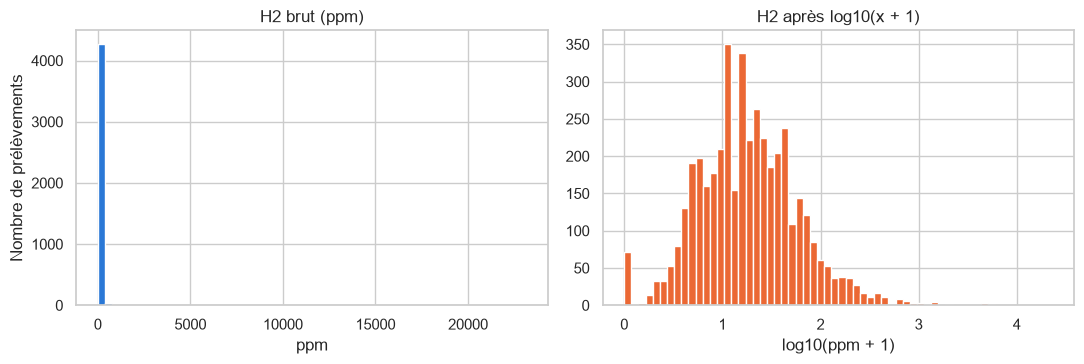

In [27]:
# Avant / après sur un exemple : l'hydrogène (H2)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(table["H2"], bins=60, color=BLEU)
axes[0].set_title("H2 brut (ppm)")
axes[0].set_xlabel("ppm")
axes[0].set_ylabel("Nombre de prélèvements")

axes[1].hist(table["log_H2"], bins=60, color=ORANGE)
axes[1].set_title("H2 après log10(x + 1)")
axes[1].set_xlabel("log10(ppm + 1)")

plt.tight_layout()
plt.show()

**Interprétation :** à gauche, presque tous les prélèvements sont tassés dans la première barre, et l'axe s'étire jusqu'à plus de 20 000 ppm
à cause de quelques valeurs. À droite, après le logarithme, la distribution est **étalée et lisible**, proche d'une forme en cloche :
on distingue désormais les transformateurs sains (autour de 1, soit ~10 ppm) et ceux qui produisent beaucoup d'hydrogène (au-delà de 2, soit plus de 100 ppm).

## 12. Normalisation et standardisation
Les deux méthodes mettent toutes les variables **à la même échelle**, pour qu'aucun gaz ne domine les autres uniquement à cause de son unité ou de son ordre de grandeur.

| Méthode | Formule | Résultat |
|---|---|---|
| **Normalisation** (Min-Max) | (x − min) / (max − min) | valeurs entre **0 et 1** |
| **Standardisation** (z-score) | (x − moyenne) / écart-type | moyenne **0**, écart-type **1** |

On les applique aux gaz **après logarithme**.

In [28]:
# Normalisation Min-Max
normaliseur = MinMaxScaler()
gaz_normalises = normaliseur.fit_transform(table[colonnes_log])   # fit = calcule min et max ; transform = applique la formule
gaz_normalises = pd.DataFrame(gaz_normalises, columns=gaz_defaut, index=table.index)

print("Après NORMALISATION : min = 0 et max = 1 pour chaque gaz")
gaz_normalises.describe().loc[["min", "max", "mean"]]

Après NORMALISATION : min = 0 et max = 1 pour chaque gaz


,H2,CH4,C2H2,C2H4,C2H6,CO,CO2
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00
mean,0.29,0.25,0.04,0.34,0.17,0.48,0.71


In [29]:
# Standardisation (z-score)
standardiseur = StandardScaler()
gaz_standardises = standardiseur.fit_transform(table[colonnes_log])
gaz_standardises = pd.DataFrame(gaz_standardises, columns=gaz_defaut, index=table.index)

print("Après STANDARDISATION : moyenne = 0 et écart-type = 1 pour chaque gaz")
gaz_standardises.describe().loc[["mean", "std", "min", "max"]]

Après STANDARDISATION : moyenne = 0 et écart-type = 1 pour chaque gaz


,H2,CH4,C2H2,C2H4,C2H6,CO,CO2
mean,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.45,-1.75,-0.50,-2.31,-1.28,-5.25,-6.72
max,5.98,5.36,12.12,4.47,6.09,5.71,2.71


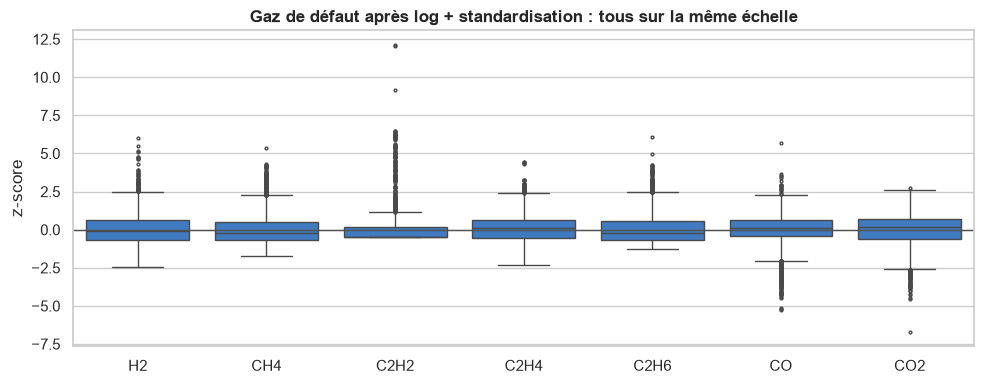

In [30]:
# Comparaison visuelle : les 7 gaz sur un même graphique, après standardisation
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=gaz_standardises, ax=ax, color=BLEU, fliersize=2)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_title("Gaz de défaut après log + standardisation : tous sur la même échelle", fontweight="bold")
ax.set_ylabel("z-score")
plt.tight_layout()
plt.show()

**Choix : la standardisation.** On la garde pour la suite car :
- l'**ACP** et la plupart des méthodes de clustering reposent sur la **variance** : la standardisation donne à chaque gaz une variance de 1, donc **le même poids** ;
- la normalisation Min-Max dépend uniquement du minimum et du maximum : une seule valeur extrême suffit à tasser toutes les autres.

Le graphique montre que les 7 gaz sont désormais **comparables** sur une même échelle, ce qui était impossible avec les valeurs brutes.

In [31]:
# On ajoute les gaz standardisés à la table (colonnes "std_<gaz>")
colonnes_std = []
for gaz in gaz_defaut:
    nom = "std_" + gaz
    table[nom] = gaz_standardises[gaz]
    colonnes_std.append(nom)

table[colonnes_std].head()

,std_H2,std_CH4,std_C2H2,std_C2H4,std_C2H6,std_CO,std_CO2
0,1.54,0.52,-0.50,-0.22,0.93,1.05,1.49
1,1.27,0.76,-0.50,-0.17,0.93,0.93,1.46
2,1.26,0.72,-0.50,-0.07,0.88,0.91,1.58
3,0.56,0.09,-0.21,0.50,0.31,0.29,0.49
4,0.29,-0.21,-0.50,0.29,0.23,0.15,0.31


## 13. Analyse en composantes principales (ACP)
**Idée :** nos 7 gaz sont liés entre eux (un même défaut produit plusieurs gaz en même temps).
L'ACP construit de **nouveaux axes** (les « composantes principales ») qui résument au mieux l'information des 7 gaz.
Si 2 axes suffisent à résumer une grande partie de l'information, on peut représenter chaque prélèvement comme **un point sur un plan**.

La **variance expliquée** d'un axe = la part de l'information totale qu'il conserve.

### 13.1 Variance expliquée par chaque composante
On calcule d'abord les 7 composantes pour voir combien d'information chacune apporte.

In [32]:
acp_complete = PCA()                     # sans préciser : autant de composantes que de variables (7)
acp_complete.fit(table[colonnes_std])

pourcentages = acp_complete.explained_variance_ratio_ * 100     # part de l'information de chaque axe, en %

variance = pd.DataFrame({
    "composante": [f"CP{i}" for i in range(1, 8)],
    "variance_expliquee_%": pourcentages.round(1),
    "variance_cumulee_%": pourcentages.cumsum().round(1),       # cumsum = somme cumulée
})
variance

,composante,variance_expliquee_%,variance_cumulee_%
0,CP1,56.40,56.40
1,CP2,17.70,74.10
2,CP3,8.30,82.40
3,CP4,7.30,89.70
4,CP5,4.80,94.40
5,CP6,3.30,97.70
6,CP7,2.30,100.00


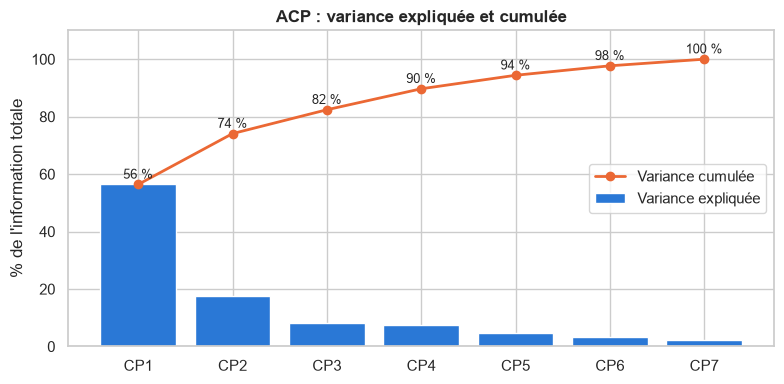

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(variance["composante"], variance["variance_expliquee_%"], color=BLEU, label="Variance expliquée")
ax.plot(variance["composante"], variance["variance_cumulee_%"], color=ORANGE, marker="o", linewidth=2, label="Variance cumulée")
for x, y in zip(variance["composante"], variance["variance_cumulee_%"]):
    ax.text(x, y + 2, f"{y:.0f} %", ha="center", fontsize=9)
ax.set_ylim(0, 110)
ax.set_ylabel("% de l'information totale")
ax.set_title("ACP : variance expliquée et cumulée", fontweight="bold")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

**Interprétation :**
- La 1re composante résume à elle seule **56 %** de l'information des 7 gaz ; la 2e en ajoute **18 %**.
- À elles deux, elles conservent **74 %** de l'information (variance cumulée).
- Les composantes suivantes apportent chacune moins de 9 % : la courbe forme un « coude » après CP2.

→ Un plan à **2 axes** suffit pour représenter correctement les prélèvements.

### 13.2 ACP à 2 composantes

In [34]:
acp = PCA(n_components=2)
coordonnees = acp.fit_transform(table[colonnes_std])   # coordonnées de chaque prélèvement sur CP1 et CP2

table["CP1"] = coordonnees[:, 0]
table["CP2"] = coordonnees[:, 1]

print(f"Variance expliquée : CP1 = {acp.explained_variance_ratio_[0]:.1%}, CP2 = {acp.explained_variance_ratio_[1]:.1%}")
print(f"Variance cumulée   : {acp.explained_variance_ratio_.sum():.1%}")

Variance expliquée : CP1 = 56.4%, CP2 = 17.7%
Variance cumulée   : 74.1%


### 13.3 Que représentent les axes ? (cercle des corrélations)
Pour interpréter un axe, on regarde la **corrélation** entre chaque gaz et cet axe (entre −1 et 1).
Un gaz proche de 1 (ou −1) sur un axe « tire » fortement cet axe.

In [35]:
# Corrélation gaz / axe = coefficient de l'axe x racine carrée de la variance de l'axe
correlations = acp.components_.T * np.sqrt(acp.explained_variance_)
correlations = pd.DataFrame(correlations, index=gaz_defaut, columns=["CP1", "CP2"])
correlations

,CP1,CP2
H2,0.74,0.25
CH4,0.87,0.20
C2H2,0.28,0.83
C2H4,0.81,-0.11
C2H6,0.84,0.20
CO,0.77,-0.43
CO2,0.77,-0.46


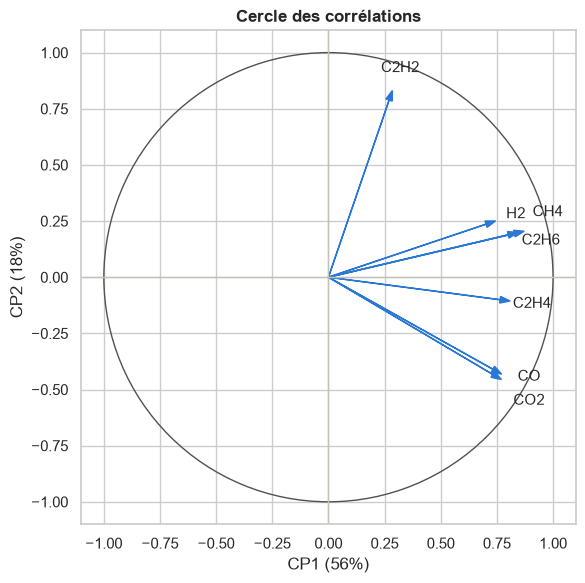

In [36]:
fig, ax = plt.subplots(figsize=(6, 6))

# Le cercle de rayon 1
cercle = plt.Circle((0, 0), 1, fill=False, color="#52514e")
ax.add_patch(cercle)

# Petits décalages d'étiquettes pour les gaz dont les flèches se superposent
decalage = {"CH4": (0.0, 0.06), "C2H6": (0.0, -0.06), "CO": (0.03, 0.04), "CO2": (0.03, -0.04)}

# Une flèche par gaz
for gaz in gaz_defaut:
    x, y = correlations.loc[gaz, "CP1"], correlations.loc[gaz, "CP2"]
    ax.arrow(0, 0, x, y, color=BLEU, head_width=0.03, length_includes_head=True)
    dx, dy = decalage.get(gaz, (0, 0))      # (0, 0) si le gaz n'a pas de décalage
    ax.text(x * 1.12 + dx, y * 1.12 + dy, gaz, ha="center", va="center", fontsize=11)

ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.set_xlabel(f"CP1 ({acp.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"CP2 ({acp.explained_variance_ratio_[1]:.0%})")
ax.set_title("Cercle des corrélations", fontweight="bold")
plt.tight_layout()
plt.show()

**Interprétation :**
- **Axe 1 (CP1, 56 %) = la quantité globale de gaz.** Toutes les flèches pointent vers la droite (corrélations de 0,74 à 0,87, sauf C2H2).
  Un prélèvement situé à droite contient **beaucoup de gaz**, à gauche **peu de gaz**.
- **Axe 2 (CP2, 18 %) = le type de problème.** Il oppose :
  - en haut, l'**acétylène (C2H2)** (0,83), signature d'un **défaut électrique** (arc) ;
  - en bas, le **CO et le CO2** (−0,43 et −0,46), signature du **vieillissement thermique du papier isolant**.
- `H2`, `CH4` et `C2H6` ont des flèches presque confondues : ces gaz **augmentent ensemble** (ils sont produits par les mêmes types de défauts).

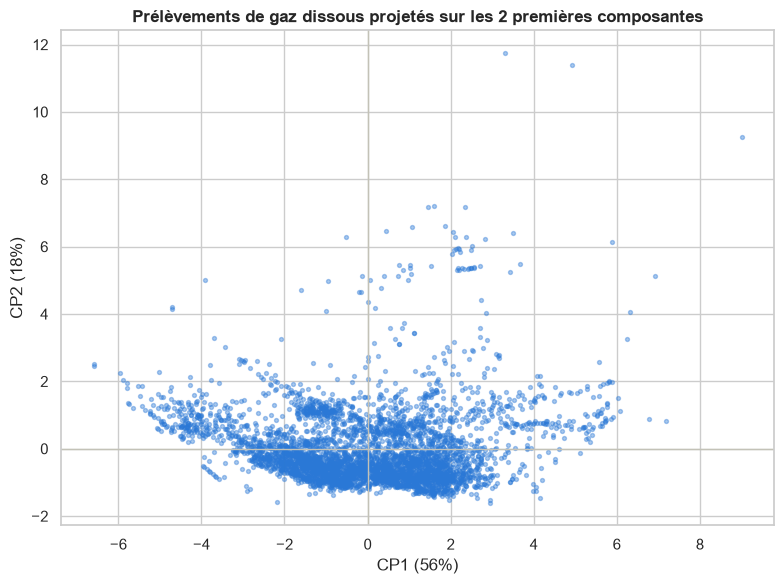

In [37]:
# Projection des prélèvements sur le plan CP1 / CP2
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(table["CP1"], table["CP2"], s=8, alpha=0.4, color=BLEU)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel(f"CP1 ({acp.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"CP2 ({acp.explained_variance_ratio_[1]:.0%})")
ax.set_title("Prélèvements de gaz dissous projetés sur les 2 premières composantes", fontweight="bold")
plt.tight_layout()
plt.show()

**Interprétation :** chaque point est un prélèvement d'huile.
- La **grande majorité** des points forme un nuage dense autour du centre, légèrement sous l'axe horizontal :
  niveaux de gaz habituels et pas d'acétylène → fonctionnement **normal**.
- **À droite** (CP1 > 3) : prélèvements très chargés en gaz → transformateurs qui **se dégradent** ou sont **en défaut**.
- **En haut** (CP2 > 3) : prélèvements contenant de l'acétylène → **suspicion d'arc électrique**, le cas le plus grave.
- **À gauche** (CP1 < −3) : très peu de gaz → huile **neuve ou récemment traitée**.

On ne voit pas de groupes nettement séparés à l'œil nu : la recherche de groupes de prélèvements sera faite par **clustering** à l'étape suivante.

## 14. Sauvegarde de la table prétraitée
La table contient maintenant :
- les identifiants, la date et les caractéristiques du transformateur (complétées) ;
- les **gaz en ppm** (valeurs réelles, utiles pour l'interprétation) ;
- les **gaz log-transformés** (`log_…`) et **standardisés** (`std_…`) pour la fouille de données ;
- les coordonnées **CP1** et **CP2** de l'ACP.

In [38]:
dossier_processed = Path.cwd() / "data" / "processed"
dossier_processed.mkdir(parents=True, exist_ok=True)

fichier = dossier_processed / "dga_transformateurs_pretraite.csv"
table.to_csv(fichier, index=False, encoding="utf-8")

print("Fichier enregistré :", fichier.relative_to(Path.cwd()))
print("Dimensions :", table.shape)
print("Colonnes :", list(table.columns))

Fichier enregistré : data\processed\dga_transformateurs_pretraite.csv
Dimensions : (4338, 35)
Colonnes : ['CléAnalyse', 'NoÉquipement', 'DatePrélèvement', 'Site', 'Manufacturier', 'Année', 'Tension', 'Puissance', 'LitreHuile', 'H2', 'CH4', 'C2H2', 'C2H4', 'C2H6', 'CO', 'CO2', 'O2', 'N2', 'Année_imputée', 'log_H2', 'log_CH4', 'log_C2H2', 'log_C2H4', 'log_C2H6', 'log_CO', 'log_CO2', 'std_H2', 'std_CH4', 'std_C2H2', 'std_C2H4', 'std_C2H6', 'std_CO', 'std_CO2', 'CP1', 'CP2']


## Bilan de l'étape 2
| Étape | Résultat |
|---|---|
| Table d'étude | 4 363 prélèvements de gaz dissous sur 293 transformateurs |
| Faux zéros | 10 prélèvements vides supprimés ; zéros impossibles transformés en NA |
| Doublons | 15 prélèvements saisis en double supprimés |
| Valeurs manquantes | 2 colonnes supprimées (`MWs`, `Température`) ; 8 colonnes complétées par la médiane |
| Variables qualitatives | noms de fabricants harmonisés (19 → 16 fabricants) |
| Valeurs aberrantes | valeurs extrêmes **conservées** (signes de défaut) ; 3 erreurs de saisie de `N2` corrigées |
| Logarithme + standardisation | les 7 gaz de défaut sont sur une même échelle |
| ACP | 2 composantes résument 74 % de l'information : quantité de gaz (CP1) et type de défaut (CP2) |
| **Table finale** | **4 338 prélèvements, 35 colonnes, aucune valeur manquante** |

**Prochaine étape :** la fouille de données (data mining) sur cette table.